# Joint Hi-C + FISH reconstruction with GEM-FISH

Hi-C gives contacts along a whole chromosome; chromatin tracing gives real distances (in nm) for a
small region.  GEM-FISH (Abbas et al. 2019, *Nat Commun* 10:2049, doi:10.1038/s41467-019-10005-6)
fuses the two into one 3-D model of a chromosome.  This tutorial runs U-Chrom's independent PyTorch
re-implementation, `uchrom.recon.fish.reconstruct_gem_fish`, on real data from the same cell line,
compares it with a Hi-C-only model to see what the imaging adds, and checks the result against the
FISH distances and the Hi-C map.

**Data**: Rao et al. 2014, *Cell* 159:1665 (in situ Hi-C, IMR90, GEO GSE63525), chr21 at 5 kb, hg19 —
`ds.load("rao2014_imr90_chr21")` gives it as a `ChromData` with the map linked (built once: a 3.8 MB `.cool`,
by HTTP range reads of the GEO `.hic`); Bintu et al. 2018, *Science* 362:eaau1783 (chromatin tracing of IMR90
chr21:20.0–21.95 Mb hg19, 65 segments of 30 kb, 1,277 imaged chromosomes) — `ds.load("bintu_imr90_hg19")`
(downloaded once from GitHub, 2 MB).
**Modules**: `uchrom.recon.fish` (`reconstruct_gem_fish`, `GEMFISHParams`), `uchrom.fea` (`rebin_map`,
`contact_matrix`, `distance_map`, `compare_distances`, `contact_agreement`).  **Runtime**: about 1 min on a
laptop CPU.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import uchrom.datasets as ds
from uchrom.fea import bin_index, compare_distances, contact_agreement, contact_matrix, distance_map, rebin_map
from uchrom.recon.fish import GEMFISHParams, reconstruct_gem_fish

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out") / "gem_fish_reconstruction"; OUT.mkdir(parents=True, exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)

hic = ds.load("rao2014_imr90_chr21")   # Rao 2014 IMR90 chr21, 5 kb, raw counts, hg19: the map linked as "bulk"
fish = ds.load("bintu_imr90_hg19")     # Bintu 2018 IMR90 chr21 tracing, segment 1 at its hg19 position
print(hic.uns["linked_cool"]["bulk"]["label"], "-", f"{hic.uns['linked_cool']['bulk']['n_contacts']:,} contacts")
print(fish)

Rao 2014 IMR90 in situ Hi-C, chr21, 5 kb - 10,266,877 contacts
ChromData: n_spots=77797, n_traces=1277, n_cells=1277, n_bins=65
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']
  uns:     ['xyz_unit', 'genome_assembly', 'source', 'dataset']


## The imaging input

`ds.load("bintu_imr90_hg19")` holds Bintu's CSV as a `ChromData` (`uchrom.io.read_bintu_tracing`): one trace
per imaged chromosome, one bin per 30 kb segment, coordinates in nm.  Segment 1 sits at its **hg19** position
(chr21:20,000,032; hg38 18,627,714 per the Bintu repository, `ds.load("bintu_imr90")`) so that it matches the
hg19 Hi-C.  `uchrom.fea.distance_map` gives the population median distance of every segment pair.

In [2]:
dm = distance_map(fish, "chr21", stat="median")
D_fish = dm.matrix
print(f"median distance map: {D_fish.shape[0]} segments, {dm.n_traces:,} traces; "
      f"median pair observed in {np.median(dm.count[np.triu_indices(len(D_fish), 1)]):.0f} traces")

median distance map: 65 segments, 1,277 traces; median pair observed in 1128 traces


## The Hi-C input on the same grid

To compare model and imaging bin by bin, `rebin_map` sums the 5 kb map into 30 kb bins whose edges fall on the
Bintu segment grid (`anchor=` the first segment's start: edges ≡ 20,000,000 mod 30 kb), so every FISH segment
maps to exactly one Hi-C bin, balances it with ICE and links it to `hic` (key `bulk_30kb`); `contact_matrix`
reads it back, and `bin_index` gives the Hi-C bin of every segment.

Rao 2014 IMR90 in situ Hi-C, chr21, 5 kb, rebinned to 30 kb (ICE-balanced): 1605 bins; FISH segments = Hi-C bins 667-731


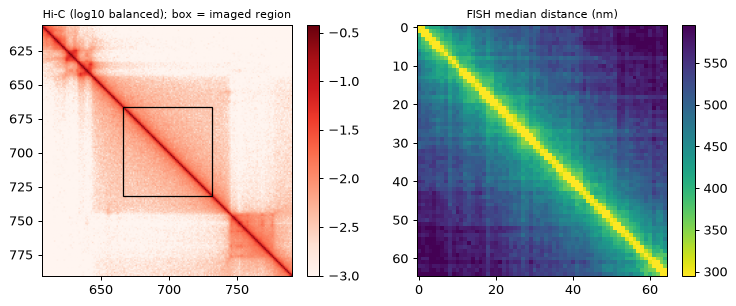

In [3]:
START = int(fish.bins["start"].min())                       # 20,000,032 (hg19)
rebin_map(hic, "bulk", resolution=30_000, anchor=START, out=OUT / "IMR90_chr21_30kb_bintu_grid.cool")
hic_bins, H = contact_matrix(hic, "bulk_30kb", chrom="chr21")
fish_idx = bin_index(hic_bins, "chr21", (dm.bins["start"] + dm.bins["end"]) // 2)   # Hi-C bin of every FISH segment
assert len(set(fish_idx)) == len(fish_idx)
print(f"{hic.uns['linked_cool']['bulk_30kb']['label']}: {len(hic_bins)} bins; "
      f"FISH segments = Hi-C bins {fish_idx[0]}-{fish_idx[-1]}")

lo, hi = fish_idx[0] - 60, fish_idx[-1] + 60
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.5))
im = ax[0].imshow(np.log10(H[lo:hi, lo:hi] + 1e-4), cmap="Reds", vmin=-3,
                  extent=[lo - 0.5, hi - 0.5, hi - 0.5, lo - 0.5])
ax[0].add_patch(plt.Rectangle((fish_idx[0] - 0.5, fish_idx[0] - 0.5), len(fish_idx), len(fish_idx),
                              fill=False, ec="k", lw=1))
ax[0].set_title("Hi-C (log10 balanced); box = imaged region", fontsize=9); fig.colorbar(im, ax=ax[0], fraction=0.046)
VMIN, VMAX = np.nanpercentile(D_fish[np.triu_indices(len(D_fish), 1)], [1, 98])
im = ax[1].imshow(D_fish, cmap="viridis_r", vmin=VMIN, vmax=VMAX); ax[1].set_title("FISH median distance (nm)", fontsize=9)
fig.colorbar(im, ax=ax[1], fraction=0.046)
fig.tight_layout()

## Running GEM-FISH

`reconstruct_gem_fish(hic, contacts="bulk_30kb", chrom="chr21", fish=fish)` works in three stages:

1. **TAD level** — partition the chromosome into TADs (Dixon directionality-index caller, or `tads=`)
   and place the TAD centres by gradient descent on Hi-C KL divergence + polymer prior (λ_E) +
   FISH inter-TAD distances (λ_F, in nm).
2. **Inside every TAD** — place its bins on intra-TAD Hi-C + polymer prior + the FISH radius of
   gyration of the TAD (λ_R).
3. **Assembly** — move every TAD to its centre and rotate it to join its neighbours.

FISH can only act through TAD-centre distances and TAD sizes, so the imaged region must span several
TADs.  With the default cap (TADs of at most 5 % of the chromosome, 80 bins = 2.4 Mb) the DI caller's
TADs are as large as the whole imaged region, which then falls into one or two TADs and the FISH terms
barely change the model.  We cap them at 1 % (16 bins, 480 kb; `tad_max_size_frac=0.01`): the imaged
region then holds five TADs.  The λ weights are this tutorial's settings, not tuned here; the optimiser
is seeded, so a CPU run is reproducible.

In [4]:
params = GEMFISHParams(lambda_E_tad=0.5, lambda_F=0.5, lambda_E_intra=0.05, lambda_R=0.01,
                       stage1_iter=500, stage1_ensemble=20, stage2_iter=300, stage2_ensemble=6,
                       tad_di_window=50, tad_di_min_size_frac=0.01, tad_max_size_frac=0.01,
                       device="cpu", verbose=False)
t0 = time.time()
gf = reconstruct_gem_fish(hic, contacts="bulk_30kb", chrom="chr21", fish=fish, params=params)
t_gf = time.time() - t0
tads = gf.results["gem_fish.tads"]                             # the TAD partition the model was built on
in_region = tads[(tads["end_bin"] > fish_idx[0]) & (tads["start_bin"] <= fish_idx[-1])]
print(f"GEM-FISH: {t_gf:.0f} s, {len(tads)} TADs, {len(in_region)} of them in the imaged region")
print(gf)
print(gf.uns["gem_fish"])
in_region

GEM-FISH: 22 s, 106 TADs, 5 of them in the imaged region
ChromData: n_spots=1605, n_traces=1, n_bins=1605
  spots:   ['chrom', 'start', 'end', 'trace_id', 'bin_id']
  results: ['gem_fish.tads']
  uns:     ['xyz_unit', 'genome_assembly', 'gem_fish']
{'n_tads': 106, 'stage1_final_loss': 777045.4835715899, 'stage1_best_ensemble': 3, 'chrom': 'chr21', 'contacts': 'bulk_30kb', 'fish': True}


,chrom,start,end,start_bin,end_bin
42,chr21,19910000,20390000,664,680
43,chr21,20390000,20780000,680,693
44,chr21,20780000,21260000,693,709
45,chr21,21260000,21740000,709,725
46,chr21,21740000,22220000,725,741


The result is a `ChromData` with one spot per Hi-C bin and one trace (a single consensus model); the TAD
partition is stored with it (`gf.results["gem_fish.tads"]`: bp and Hi-C bin indices, end exclusive), and
`return_intermediate=True` also returns the stage outputs (TAD centres, per-TAD coordinates, the FISH targets,
loss histories).

For comparison, the same run without imaging (`fish=None`, a Hi-C-only model):

In [5]:
t0 = time.time()
hic_only = reconstruct_gem_fish(hic, contacts="bulk_30kb", chrom="chr21", params=params)
print(f"Hi-C only: {time.time() - t0:.0f} s; final stage-1 loss {hic_only.uns['gem_fish']['stage1_final_loss']:.3g} "
      f"(with FISH: {gf.uns['gem_fish']['stage1_final_loss']:.3g})")
gf.write(OUT / "IMR90_chr21_gemfish.chromdata.zarr")
hic_only.write(OUT / "IMR90_chr21_hic_only.chromdata.zarr")

Hi-C only: 20 s; final stage-1 loss 96 (with FISH: 7.77e+05)


## Agreement with the imaged distances

`compare_distances(model, fish)` puts both on the model's bins (every FISH segment into the bin that holds its
midpoint), takes the median distance of every bin pair over the imaged chromosomes (the model is one structure),
and compares the two matrices: Pearson r, and GEM-FISH's error measure, the mean relative error
|s·d_model − d_FISH| / d_FISH after rescaling the model by the least-squares factor s (`scale`, nm per model
unit).  For the GEM-FISH model the same FISH data were restraints, so this is a fit, not a held-out score; the
Hi-C-only model never saw them.

In [6]:
vs_fish = {name: compare_distances(cd, fish) for name, cd in (("Hi-C + FISH", gf), ("Hi-C only", hic_only))}
pd.DataFrame({name: {"pearson": v.pearson, "rel_error": v.rel_error, "scale_nm": v.scale}
              for name, v in vs_fish.items()}).T.round(3)

,pearson,rel_error,scale_nm
Hi-C + FISH,0.750,0.327,20.758
Hi-C only,0.675,0.277,48.148


## Agreement with the Hi-C map

The model should also reproduce the contact map: high contact frequency ↔ short distance.
`contact_agreement(model, hic, contacts="bulk_30kb")` computes the Spearman correlation between the balanced
contacts and `1 / d` over the whole chromosome, raw and after removing the distance decay (observed / expected
on both sides); `max_separation=` keeps the pairs within 3 Mb.

In [7]:
def hic_scores(cd):
    out = {}
    for label, sep in (("all pairs", None), ("<= 3 Mb", 3_000_000)):
        v = contact_agreement(cd, hic, contacts="bulk_30kb", max_separation=sep)
        out[f"raw, {label}"], out[f"O/E, {label}"] = v.spearman, v.spearman_oe
    return out


pd.DataFrame({name: hic_scores(cd) for name, cd in (("Hi-C + FISH", gf), ("Hi-C only", hic_only))}).T.round(3)

,"raw, all pairs","O/E, all pairs","raw, <= 3 Mb","O/E, <= 3 Mb"
Hi-C + FISH,-0.029,-0.085,0.057,-0.124
Hi-C only,0.407,0.168,0.702,0.311


The Hi-C-only model follows the contact map; the FISH-constrained one loses it over the whole
chromosome.  The FISH term of stage 1 compares model distances, in units of order 1, with FISH distances
in nm: it dominates the stage-1 loss (printed above: about 8 × 10⁵ with FISH, about 10² without), so the arrangement of
all 106 TAD centres is driven by the five imaged ones instead of by the Hi-C.  In 3-D the imaged region
(black) is stretched out at the edge of an otherwise compact chromosome:

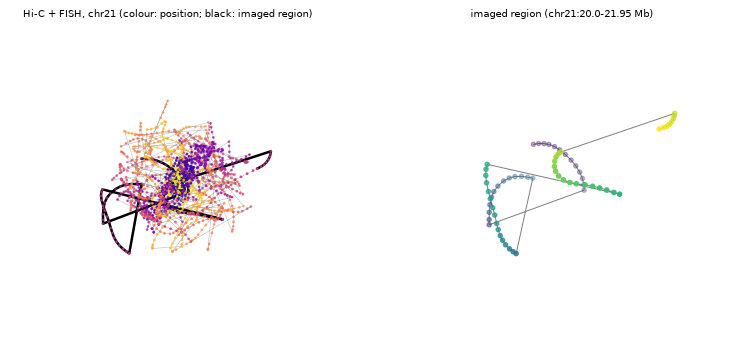

In [8]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers the 3-D projection)

loci = gf.spots_with_loci()
region = ((loci["end"] > START) & (loci["start"] < dm.bins["end"].max())).to_numpy()
fig = plt.figure(figsize=(9, 4))
ax = fig.add_subplot(1, 2, 1, projection="3d")
X = gf.coords
ax.plot(*X.T, lw=0.4, color="0.7")
ax.scatter(*X.T, c=np.arange(len(X)), cmap="plasma", s=1.5)
ax.plot(*X[region].T, lw=2, color="k")
ax.set_title("Hi-C + FISH, chr21 (colour: position; black: imaged region)", fontsize=8); ax.set_axis_off()
ax = fig.add_subplot(1, 2, 2, projection="3d")
Z = X[region]
ax.plot(*Z.T, lw=0.8, color="0.5"); ax.scatter(*Z.T, c=np.arange(len(Z)), cmap="viridis", s=12)
ax.set_title("imaged region (chr21:20.0-21.95 Mb)", fontsize=8); ax.set_axis_off()
fig.tight_layout()

## Modelling only the imaged TADs

In the GEM-FISH paper every modelled TAD was imaged (Wang et al. 2016 traced TAD centres along whole
chromosomes).  `tads=` (a table of `start` / `end` in bp) sets the partition and restricts the model to
those windows, so we can reproduce that situation here: the five DI TADs that overlap the imaged region
(`in_region`, from the stored partition above), or the whole region as one domain.  Every modelled TAD then has FISH data, as in
the paper.  Each run takes a few seconds.

In [9]:
runs = {(f"chr21, {len(tads)} TADs", "Hi-C + FISH"): gf, (f"chr21, {len(tads)} TADs", "Hi-C only"): hic_only}
one_domain = pd.DataFrame({"start": [in_region["start"].min()], "end": [in_region["end"].max()]})
t0 = time.time()
for label, windows in (("imaged TADs (5)", in_region[["start", "end"]]), ("imaged region, 1 domain", one_domain)):
    for inputs, f in (("Hi-C + FISH", fish), ("Hi-C only", None)):
        runs[(label, inputs)] = reconstruct_gem_fish(hic, contacts="bulk_30kb", chrom="chr21", fish=f, tads=windows,
                                                     params=params)
print(f"4 region models in {time.time() - t0:.0f} s, {runs[('imaged TADs (5)', 'Hi-C only')].n_spots} bins each "
      f"(chr21:{one_domain['start'][0]:,}-{one_domain['end'][0]:,})")

rows, mats = [], {}
for (model, inputs), cd in runs.items():
    fs = compare_distances(cd, fish)
    hs = contact_agreement(cd, hic, contacts="bulk_30kb")
    mats[(model, inputs)] = fs.model * fs.scale                 # model distances on the FISH bins, in nm
    rows.append({"model": model, "inputs": inputs, "r vs FISH": fs.pearson, "rel. error vs FISH": fs.rel_error,
                 "Spearman vs Hi-C": hs.spearman, "Spearman vs Hi-C (O/E)": hs.spearman_oe})
summary = pd.DataFrame(rows).set_index(["model", "inputs"])
summary.round(3)

4 region models in 4 s, 77 bins each (chr21:19,910,000-22,220,000)


r vs FISH  rel. error vs FISH  \
model                   inputs                                       
chr21, 106 TADs         Hi-C + FISH      0.750               0.327   
                        Hi-C only        0.675               0.277   
imaged TADs (5)         Hi-C + FISH      0.643               0.290   
                        Hi-C only        0.793               0.414   
imaged region, 1 domain Hi-C + FISH      0.900               0.298   
                        Hi-C only        0.901               0.297   

                                     Spearman vs Hi-C  Spearman vs Hi-C (O/E)  
model                   inputs                                                 
chr21, 106 TADs         Hi-C + FISH            -0.029                  -0.085  
                        Hi-C only               0.407                   0.168  
imaged TADs (5)         Hi-C + FISH             0.608                   0.025  
                        Hi-C only               0.823                   0.066  
imaged region, 1 domain Hi-C + FISH             0.850                   0.056  
                        Hi-C only               0.851                   0.057

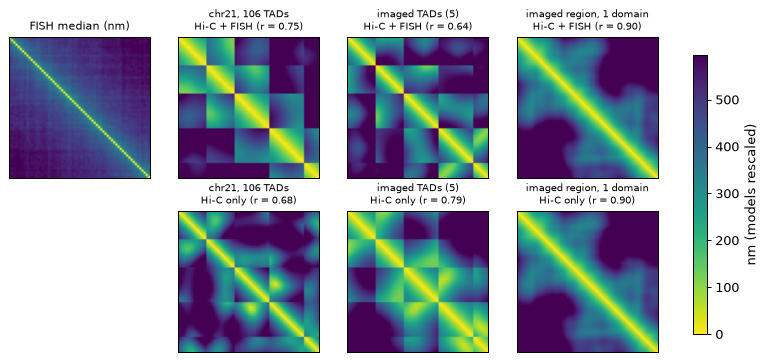

In [10]:
models = list(dict.fromkeys(m for m, _ in runs))
fig, axes = plt.subplots(2, len(models) + 1, figsize=(10, 4.6))
axes[0, 0].imshow(D_fish, cmap="viridis_r", vmin=0, vmax=VMAX); axes[0, 0].set_title("FISH median (nm)", fontsize=9)
axes[1, 0].set_axis_off()
for c, model in enumerate(models, start=1):
    for r, inputs in enumerate(("Hi-C + FISH", "Hi-C only")):
        im = axes[r, c].imshow(mats[(model, inputs)], cmap="viridis_r", vmin=0, vmax=VMAX)
        axes[r, c].set_title(f"{model}\n{inputs} (r = {summary.loc[(model, inputs), 'r vs FISH']:.2f})", fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
cb = fig.colorbar(im, ax=axes, fraction=0.02, label="nm (models rescaled)")

## Notes and caveats

* **What the imaging adds — on this data, little.**  Over the imaged region the Hi-C-only models match the
  imaged distances as well as or better than the FISH-constrained ones (summary table: r 0.79 vs 0.64
  with the five imaged TADs, 0.90 vs 0.90 with the region as one domain).  FISH lowers the relative
  error of the five-TAD model (0.41 → 0.29) and raises r of the whole-chromosome model (0.68 → 0.75), at
  the cost described next.  With the default TAD cap (5 %) the region falls into one or two TADs and
  FISH changes r by less than 0.01 (0.705 → 0.710 in a run not shown).  The FISH data are restraints
  here, so no FISH score is held out — and still the Hi-C alone does as well; the closest description
  of the imaged distances is the Hi-C model of the region as one domain.
* **Partial FISH coverage distorts the whole model.**  With FISH for a few TADs of a whole chromosome,
  the nm-valued FISH term dominates the TAD-level loss and the assembled model no longer reproduces the
  Hi-C.  This re-implementation does not balance the FISH term against the unit-scale terms (λ_F is an
  absolute weight); model only imaged TADs (`tads=`), or use the Hi-C-only model outside the imaged
  region.
* **Assembly** is a one-anchor Kabsch rotation per TAD, a simplification of the paper's gradient-descent
  assembly; it leaves visible jumps between consecutive TADs (the block pattern of the distance maps).
* **Weights.**  The paper's λ values (λ_E = 5 × 10¹², λ_F = 10⁻⁸) are for raw counts without row
  normalisation; this re-implementation row-normalises inside the KL term, so its weights differ.
* **Not a benchmark.**  The paper's evaluation (Wang 2016 TAD-centre FISH, TAD-level distances) is
  an unpublished benchmark.
* **Other chromosomes** are sliced from the same Rao 2014 map the same way as chr21 here
  (`uchrom.datasets._builders.slice_hic(cell="IMR90", chroms=["20"], res=5000, out=...)`, HTTP range reads
  of the GEO `.hic`).  Do not pair IMR90 imaging with K562 Hi-C (`rao2014_k562_chr21`).
* **Device**: `device="auto"` uses CUDA / Apple MPS; results then differ from the CPU run (float32 and a
  different random stream).

## Supplement (synthetic data): the three stages on a known structure

*This part uses a simulated chain, not real data.*  It shows the mechanics of the three stages with a
ground truth to compare against — five compact TADs, contacts generated as `1 / (1 + d)`, noisy FISH
centre distances and radii of gyration — through the internal stage functions that
`reconstruct_gem_fish` chains together.

stage 1, TAD-centre distances vs truth: r = 1.000
stage 2, mean intra-TAD distance r = 0.925
assembled chain, all distances vs truth: r = 0.910


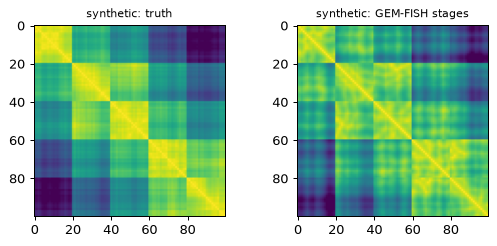

In [11]:
from scipy.spatial.distance import cdist

from uchrom.recon.fish._assembly import assemble
from uchrom.recon.fish._hic import contact_to_distance
from uchrom.recon.fish._intra_tad import Stage2Params, reconstruct_intra_tad
from uchrom.recon.fish._tad_level import Stage1Params, reconstruct_tad_level

rng = np.random.default_rng(0)
n_tads, per_tad = 5, 20
truth, centre = [], np.zeros(3)
for t in range(n_tads):
    walk = np.cumsum(rng.normal(0, 0.3, (per_tad, 3)), axis=0)
    truth.append(walk - walk.mean(0) + centre)
    centre = centre + 5.0 * (np.array([1.0, 0, 0]) + 0.3 * rng.normal(0, 1, 3))
truth = np.vstack(truth)
windows = [(t * per_tad, (t + 1) * per_tad) for t in range(n_tads)]
D_true = cdist(truth, truth)
contacts_syn = 1.0 / (1.0 + D_true); np.fill_diagonal(contacts_syn, 0)
inter = np.array([[contacts_syn[a:b, c:d].sum() for c, d in windows] for a, b in windows])
centres_true = np.array([truth[a:b].mean(0) for a, b in windows])
F = cdist(centres_true, centres_true) + rng.normal(0, 0.1, (n_tads, n_tads)); np.fill_diagonal(F, 0)
rg2 = [((truth[a:b] - truth[a:b].mean(0)) ** 2).sum(1).mean() * (1 + 0.05 * rng.standard_normal()) for a, b in windows]

centres, _ = reconstruct_tad_level(inter, F, params=Stage1Params(lambda_E=0.05, lambda_F=0.5, n_iter=500,
                                                                   n_ensemble=20, device="cpu"))
intra, _ = reconstruct_intra_tad(contacts_syn, windows, target_rg_sq_per_tad=rg2,
                                 params=Stage2Params(lambda_E=0.05, lambda_R=0.01, n_iter=300, n_ensemble=6, device="cpu"))
mid = np.array([(a + b - 1) / 2 * per_tad for a, b in windows])
gap = contact_to_distance(inter, genomic_distances=np.abs(mid[:, None] - mid[None]).astype(float),
                          alpha=0.25, fallback_c=1.0, fallback_beta=0.5)
final = assemble(centres, intra, inter_tad_distances=gap)

iu5, iuN = np.triu_indices(n_tads, 1), np.triu_indices(len(truth), 1)
print(f"stage 1, TAD-centre distances vs truth: r = {np.corrcoef(cdist(centres, centres)[iu5], cdist(centres_true, centres_true)[iu5])[0, 1]:.3f}")
print(f"stage 2, mean intra-TAD distance r = "
      f"{np.mean([np.corrcoef(cdist(intra[k], intra[k])[np.triu_indices(per_tad, 1)], D_true[a:b, a:b][np.triu_indices(per_tad, 1)])[0, 1] for k, (a, b) in enumerate(windows)]):.3f}")
print(f"assembled chain, all distances vs truth: r = {np.corrcoef(cdist(final, final)[iuN], D_true[iuN])[0, 1]:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(6, 2.8))
for a, (title, M) in zip(ax, [("truth", D_true), ("GEM-FISH stages", cdist(final, final))]):
    a.imshow(M, cmap="viridis_r", vmax=np.percentile(D_true, 98)); a.set_title(f"synthetic: {title}", fontsize=9)
fig.tight_layout()

## Next steps

* `bulk_reconstruction` — the same Hi-C map with MDS and IGM population deconvolution, checked
  against the same tracing data.
* `reconstruction` — single-cell Hi-C to 3-D (NucDynamics, EMber).
* `tad_calling`, `fish_imputation` — more analyses of chromatin-tracing data.